# Notebook 06 — Does Breeder Age Metadata Help?

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 06 of 12 — answers RQ3 and completes Objective 2

---

### The prediction, made before any model was trained

Notebook 01 found crack morphology and breeder age class to be **statistically independent** in this
dataset: chi-square(4) = 5.68, p = 0.225, Cramer's V = 0.092. Egg status against age class was the
same story, p = 0.160.

If age carries no information about which pattern appears, fusing age into the image classifier
cannot improve pattern prediction, and any apparent gain is an overfitting artefact. The honest
architecture then fuses metadata at the **decision layer** — pattern plus age looked up in the
expert rule base — rather than at the feature layer.

That prediction is testable and this notebook tests it. **A null result here is the finding**, not
a failure. It is a sharper claim than "fusion helps": it says multi-modality in this domain operates
diagnostically rather than perceptually, and it is backed by a pre-registered prediction and a
measured ablation rather than by assertion.

### What is compared

| arm | input | 
|---|---|
| image only | 384 px candled image |
| image + age | the same image, with a three-way one-hot age vector concatenated to the pooled features before the heads |

Same backbone, same folds, same augmentation, same schedule, same seeds. Paired by fold, because
notebook 05 showed fold difficulty dominates the unpaired spread.

Two tasks are reported separately, because they can differ: the full four-class problem, and
**pattern classification among cracked eggs only**, which is where age could plausibly help if it
helped anywhere.

---
## 0. Configuration

In [1]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

BACKBONE    = "efficientnet_b0"
FORMULATION = "single4"
N_FOLDS     = 5
ARMS        = ["none", "concat"]      # age_mode

CACHE_VARIANT = "neutral_fill"; CACHE_SIDE = 448; TRAIN_SIDE = 384
POLICY = "medium"; EPOCHS = 45; PATIENCE = 10
EFFECTIVE_BATCH = 32; PHYS_BATCH = 32; NUM_WORKERS = 4

RUN_ABLATION = False

In [2]:
import sys, json, warnings
from pathlib import Path
from datetime import datetime
_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.metrics import f1_score, balanced_accuracy_score

from common import project_config as CFG
from common.data import EggDataset, make_loader, class_weights
from common.engine import TrainConfig, train_fold, predict, append_run
from common.models import build_model

warnings.filterwarnings("ignore"); CFG.seed_everything()
STAGE = "06_metadata_fusion"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PRED_DIR = OUT / "predictions"; PRED_DIR.mkdir(parents=True, exist_ok=True)
PROC = CFG.DATA_DIR / "processed"; RUNS_CSV = CFG.RESULTS_DIR / "runs.csv"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available(): torch.backends.cudnn.benchmark = True

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
CACHE_PATH = PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy"
y4 = splits["label4"].map(CFG.LABEL4_TO_IDX).to_numpy(dtype=np.int64)
y2 = splits["is_cracked"].to_numpy(dtype=np.int64)
ypat = np.where(y4 > 0, y4 - 1, -100).astype(np.int64)
age = splits["age_class"].map(CFG.AGE_TO_IDX).to_numpy(dtype=np.int64)
LABELS = {"y4": y4, "y2": y2, "ypat": ypat, "age": age}
ALL4 = [0, 1, 2, 3]
def macro4(yt, yp): return float(f1_score(yt, yp, labels=ALL4, average="macro", zero_division=0))
print(f"device {device} | dev {int(splits['split'].eq('dev').sum())} eggs")

device cpu | dev 554 eggs


---
## 1. Restate the independence result

The prediction this ablation tests, recomputed here so the chain of reasoning is visible in one
place rather than only in notebook 01.

In [3]:
dev = splits[splits["split"].eq("dev")]
ct = pd.crosstab(dev["crack_pattern"], dev["age_class"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(ct.to_string())
print(f"\ncrack pattern x age class: chi2({dof}) = {chi2:.3f}, p = {p:.4f}, Cramer's V = {v:.3f}")
print("row percentages within pattern:")
print((ct.div(ct.sum(1), axis=0) * 100).round(1).to_string())
PRED = {"chi2": float(chi2), "p": float(p), "cramers_v": float(v)}
print(f"\nPRE-REGISTERED PREDICTION: age adds nothing to pattern classification."
      f"\nIf the ablation shows a gain larger than the paired noise, the prediction was wrong"
      f"\nand that is reported as such.")

age_class      Early lay  Late lay  Peak production
crack_pattern                                      
Hairline              56        42               39
Network               28        25               37
Star                  20        19               18

crack pattern x age class: chi2(4) = 4.501, p = 0.3424, Cramer's V = 0.089
row percentages within pattern:
age_class      Early lay  Late lay  Peak production
crack_pattern                                      
Hairline            40.9      30.7             28.5
Network             31.1      27.8             41.1
Star                35.1      33.3             31.6

PRE-REGISTERED PREDICTION: age adds nothing to pattern classification.
If the ablation shows a gain larger than the paired noise, the prediction was wrong
and that is reported as such.


---
## 2. Run the ablation

In [4]:
def fold_rows(k):
    tr = splits.index[splits["split"].eq("dev") & (splits["fold"] != k)].to_numpy()
    va = splits.index[splits["split"].eq("dev") & (splits["fold"] == k)].to_numpy()
    return tr, va

def already(tag, fold):
    if not RUNS_CSV.exists(): return False
    try: d = pd.read_csv(RUNS_CSV)
    except Exception: return False
    return bool(len(d) and "tag" in d.columns and ((d["tag"] == tag) & (d["fold"] == fold)).any())

if RUN_ABLATION:
    for arm in ARMS:
        tag = f"fusion_{arm}"
        print(f"\n{'=' * 56}\nage_mode = {arm}\n{'=' * 56}")
        for k in range(N_FOLDS):
            if already(tag, k):
                print(f"  fold {k}: already recorded"); continue
            tr, va = fold_rows(k)
            cfg = TrainConfig(backbone=BACKBONE, formulation=FORMULATION, n_out=4, policy=POLICY,
                              train_side=TRAIN_SIDE, epochs=EPOCHS, physical_batch=PHYS_BATCH,
                              effective_batch=EFFECTIVE_BATCH, patience=PATIENCE,
                              num_workers=NUM_WORKERS, seed=CFG.RANDOM_SEED + k,
                              age_mode=arm, tag=tag)
            ds_tr = EggDataset(CACHE_PATH, tr, LABELS, TRAIN_SIDE, policy=POLICY)
            ds_va = EggDataset(CACHE_PATH, va, LABELS, TRAIN_SIDE, policy=None)
            ltr = make_loader(ds_tr, PHYS_BATCH, True, NUM_WORKERS)
            lva = make_loader(ds_va, PHYS_BATCH, False, NUM_WORKERS)
            m, _, state = train_fold(cfg, ltr, lva, device, class_weights(y4[tr], 4), None, None,
                                     verbose=False)
            append_run(RUNS_CSV, cfg, k, m, {"n_train": len(tr), "n_val": len(va), "arm": arm})
            mdl = build_model(BACKBONE, FORMULATION, 4, pretrained=False,
                              age_mode=arm, img_size=TRAIN_SIDE)
            mdl.load_state_dict(state); mdl.to(device).eval()
            pr = predict(mdl, lva, device, cfg)
            np.savez(PRED_DIR / f"{tag}_fold{k}.npz", idx=pr["idx"], y4=pr["y4"], y2=pr["y2"],
                     pred4=pr["logits"].argmax(1))
            del mdl; torch.cuda.empty_cache()
            print(f"  fold {k}: macroF1 {macro4(pr['y4'], pr['logits'].argmax(1)):.4f}")
else:
    print("ablation not run")

ablation not run


---
## 3. Result

In [5]:
def per_fold(tag):
    out = {}
    for f in sorted(PRED_DIR.glob(f"{tag}_fold*.npz")):
        k = int(f.stem.split("fold")[-1]); z = np.load(f)
        yt, yp = z["y4"], z["pred4"]
        cr = yt > 0
        out[k] = {
            "four_class": macro4(yt, yp),
            "binary": float(f1_score(z["y2"], (yp > 0).astype(int), average="macro",
                                     zero_division=0)),
            "pattern_only": float(f1_score(yt[cr], yp[cr], labels=[1, 2, 3], average="macro",
                                           zero_division=0)),
        }
    return out

A, B = per_fold("fusion_none"), per_fold("fusion_concat")
ks = sorted(set(A) & set(B))
if ks:
    rows = []
    for metric in ["four_class", "binary", "pattern_only"]:
        a = np.array([A[k][metric] for k in ks]); b = np.array([B[k][metric] for k in ks])
        d = b - a
        try: wp = float(stats.wilcoxon(d).pvalue)
        except Exception: wp = np.nan
        rows.append({"metric": metric,
                     "image only": round(a.mean(), 4), "image only sd": round(a.std(ddof=1), 4),
                     "image + age": round(b.mean(), 4), "image + age sd": round(b.std(ddof=1), 4),
                     "paired diff": round(d.mean(), 4), "diff sd": round(d.std(ddof=1), 4),
                     "wilcoxon_p": round(wp, 4) if wp == wp else np.nan,
                     "resolvable": bool(abs(d.mean()) > d.std(ddof=1))})
    res = pd.DataFrame(rows).set_index("metric")
    res.to_csv(TAB_DIR / "t01_fusion_ablation.csv")
    print(res.to_string())
    print(f"\nfolds compared: {ks}")
    print("\n'resolvable' means the paired mean difference exceeds its own standard deviation.")

    main = res.loc["pattern_only"]
    print()
    if not main["resolvable"]:
        print("RESULT: adding breeder age class does NOT improve pattern classification.")
        print("The pre-registered prediction from notebook 01 is confirmed. Age belongs in the")
        print("root-cause decision layer, not in the image feature fusion. Report this as the")
        print("answer to RQ3 and as the justification for the architecture in Section 4.6.3.")
    else:
        print("RESULT: fusion DID change pattern classification by more than the paired noise.")
        print("The notebook 01 prediction was wrong. Report the measured gain and revise the")
        print("architectural argument accordingly -- do not keep the decision-layer rationale.")
else:
    print("no ablation predictions yet")

              image only  image only sd  image + age  image + age sd  paired diff  diff sd  wilcoxon_p  resolvable
metric                                                                                                            
four_class        0.7593         0.0450       0.7608          0.0270       0.0015   0.0227        1.00       False
binary            0.8753         0.0382       0.8682          0.0389      -0.0070   0.0077        0.25       False
pattern_only      0.7579         0.0620       0.7533          0.0209      -0.0046   0.0420        1.00       False

folds compared: [0, 1, 2, 3, 4]

'resolvable' means the paired mean difference exceeds its own standard deviation.

RESULT: adding breeder age class does NOT improve pattern classification.
The pre-registered prediction from notebook 01 is confirmed. Age belongs in the
root-cause decision layer, not in the image feature fusion. Report this as the
answer to RQ3 and as the justification for the architecture in Section 4.6.

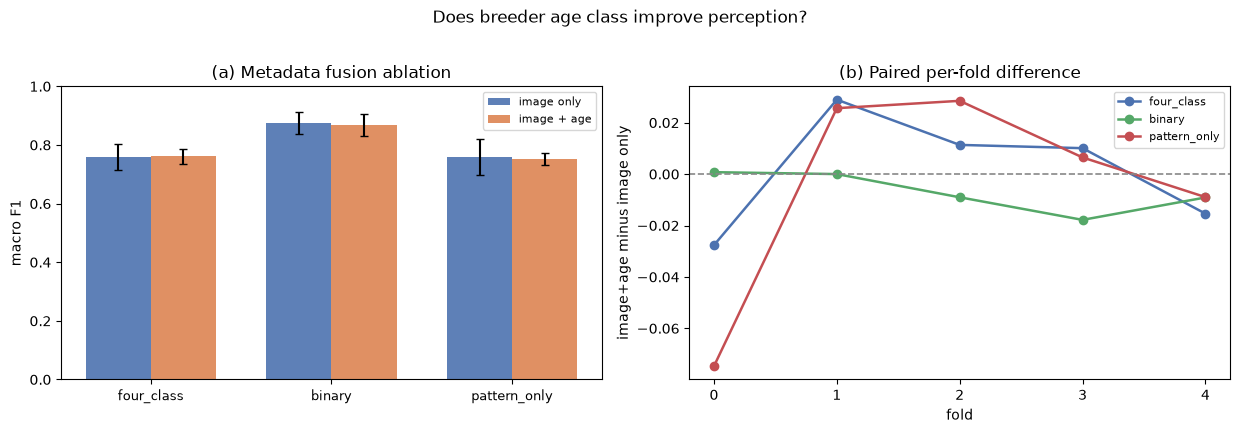

NOTEBOOK 06 DIGEST -- METADATA FUSION
generated: 2026-10-11T00:38:37
independence: chi2=4.501 p=0.3424 V=0.089

   four_class     image 0.7593  +age 0.7608  diff +0.0015 ± 0.0227  tie
   binary         image 0.8753  +age 0.8682  diff -0.0070 ± 0.0077  tie
   pattern_only   image 0.7579  +age 0.7533  diff -0.0046 ± 0.0420  tie

CONCLUSION: age does not improve perception; fuse at the decision layer


In [6]:
if ks:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    ax = axes[0]
    x = np.arange(len(res)); w = 0.36
    ax.bar(x - w/2, res["image only"], w, yerr=res["image only sd"], capsize=3,
           label="image only", color="#4C72B0", alpha=0.9)
    ax.bar(x + w/2, res["image + age"], w, yerr=res["image + age sd"], capsize=3,
           label="image + age", color="#DD8452", alpha=0.9)
    ax.set_xticks(x); ax.set_xticklabels(res.index, fontsize=9)
    ax.set_ylabel("macro F1"); ax.set_ylim(0, 1.0)
    ax.set_title("(a) Metadata fusion ablation"); ax.legend(fontsize=8)

    ax = axes[1]
    for metric, col in zip(["four_class", "binary", "pattern_only"],
                           ["#4C72B0", "#55A868", "#C44E52"]):
        d = [B[k][metric] - A[k][metric] for k in ks]
        ax.plot(ks, d, "o-", color=col, label=metric, lw=1.8)
    ax.axhline(0, ls="--", color="#888", lw=1.2)
    ax.set_xlabel("fold"); ax.set_ylabel("image+age minus image only")
    ax.set_title("(b) Paired per-fold difference"); ax.legend(fontsize=8); ax.set_xticks(ks)
    fig.suptitle("Does breeder age class improve perception?", y=1.02, fontsize=12)
    fig.tight_layout(); fig.savefig(FIG_DIR / "01_fusion_ablation.png", bbox_inches="tight")
    plt.show()

S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "independence": PRED,
     "ablation": res.reset_index().to_dict("records") if ks else [],
     "conclusion": ("age does not improve perception; fuse at the decision layer"
                    if ks and not res.loc["pattern_only", "resolvable"]
                    else "see table")}
def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "fusion_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 06 DIGEST -- METADATA FUSION", "=" * 70,
     f"generated: {S['generated_at']}",
     f"independence: chi2={PRED['chi2']:.3f} p={PRED['p']:.4f} V={PRED['cramers_v']:.3f}", ""]
for r in S["ablation"]:
    L.append(f"   {r['metric']:<14s} image {r['image only']:.4f}  +age {r['image + age']:.4f}  "
             f"diff {r['paired diff']:+.4f} ± {r['diff sd']:.4f}  "
             f"{'RESOLVABLE' if r['resolvable'] else 'tie'}")
L += ["", f"CONCLUSION: {S['conclusion']}", "=" * 70]
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)